# Ames 房价预测：街区中位价、Ridge 与 CatBoost

能否用房屋面积、质量和街区把成交价估得比街区中位价更准？输入是 79 个房屋及交易字段，输出是每套房的美元估价。我们在 Kaggle 竞赛训练集上用同一组五折比较三个模型，并用每套房只参加一次验证的折外预测检查难例。

从本目录执行 **Run All** 可重建 `results/`。阅读入口见[项目概览](README.md)和[详细实验报告](docs/experiment_report.md)。

In [1]:
import hashlib
import io
import os
import zipfile
from importlib.metadata import version
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
OUT = Path(os.environ.get("HOUSE_PRICES_OUTPUT_DIR", "results"))
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

print("  |  ".join(f"{p} {version(p)}" for p in ("numpy", "pandas", "scikit-learn", "catboost", "matplotlib")))

numpy 2.5.3  |  pandas 3.1.1  |  scikit-learn 1.9.1  |  catboost 1.2.10  |  matplotlib 3.11.2


## 1. 读取及核验竞赛数据

优先读取 `HOUSE_PRICES_DATA_DIR` 指定的目录，其次查找本地 `data/` 和 Kaggle 的挂载目录。缺少本地文件时可下载公开副本第 1 版。指定目录有误会报错，便于排查。三个 CSV 统一换行后逐一核对 SHA-256，再核对训练表、测试表与样表的编号和列结构。

In [2]:
FILES = {
    "train.csv": "1e18addf81e5e4d347cc17ee6075bbe4a42b7fa26b9e5b063e8f692a5f929d41",
    "test.csv": "8fdd3d829d4d986b58f845c9553b225e67dd8383624d90fb6ca1d4bed5798c1e",
    "sample_submission.csv": "f19e99699b925aa3085c8d2ae43c62f15fbcd35e4a953b98025f8392c3ffa807",
}
PUBLIC_ARCHIVE = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "shadalishah/house-prices-advanced-regression-techniques?datasetVersionNumber=1"
)


def checked_bytes(name, content):
    normalized = content.replace(b"\r\n", b"\n")
    if hashlib.sha256(normalized).hexdigest() != FILES[name]:
        raise ValueError(f"{name} 的校验值不符，请检查数据来源。")
    return normalized


def read_inputs():
    custom_path = os.environ.get("HOUSE_PRICES_DATA_DIR")
    if custom_path:
        roots = [Path(custom_path)]
    else:
        roots = [Path("data")]
        mount = Path("/kaggle/input")
        if mount.is_dir():
            roots += sorted(p.parent for p in mount.rglob("sample_submission.csv"))
    for root in roots:
        if all((root / name).is_file() for name in FILES):
            return {name: checked_bytes(name, (root / name).read_bytes()) for name in FILES}
    if custom_path:
        raise FileNotFoundError("指定的数据目录应同时包含 train.csv、test.csv 和 sample_submission.csv。")
    request = Request(PUBLIC_ARCHIVE, headers={"User-Agent": "Ames-House-Prices/1.0"})
    with urlopen(request, timeout=60) as response:
        with zipfile.ZipFile(io.BytesIO(response.read())) as archive:
            return {name: checked_bytes(name, archive.read(name)) for name in FILES}


raw_inputs = read_inputs()
train = pd.read_csv(io.BytesIO(raw_inputs["train.csv"]))
test = pd.read_csv(io.BytesIO(raw_inputs["test.csv"]))
sample = pd.read_csv(io.BytesIO(raw_inputs["sample_submission.csv"]))
assert train.shape == (1460, 81) and test.shape == (1459, 80)
assert train.drop(columns="SalePrice").columns.equals(test.columns)
assert list(sample.columns) == ["Id", "SalePrice"] and test["Id"].equals(sample["Id"])
assert train["Id"].is_unique and test["Id"].is_unique and not train["Id"].isin(test["Id"]).any()
y = train["SalePrice"].astype(float)
assert (np.isfinite(y) & y.gt(0)).all()
print(f"训练集 {len(train):,} 笔，测试集 {len(test):,} 套，每套房有 {test.shape[1]-1} 个原始特征。")

训练集 1,460 笔，测试集 1,459 套，每套房有 79 个原始特征。


## 2. 价格分布、缺失值与面积

先看目标的量级和右尾，再看缺失集中在哪些字段，最后把面积与质量一起画出来。以下三图只使用带标签的训练集。

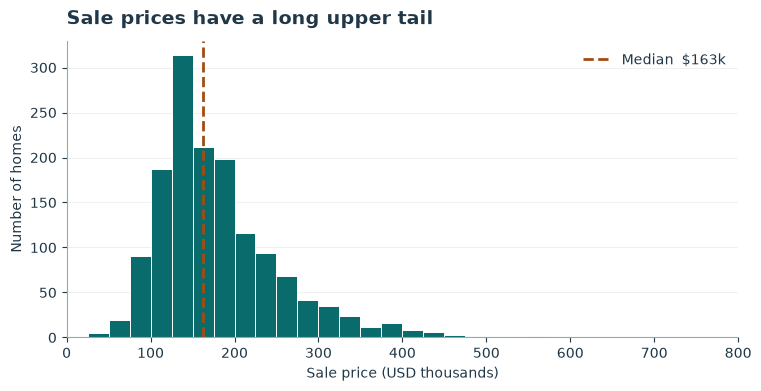

成交价中位数为 $163,000，第 90 百分位为 $278,000。后续模型拟合自然对数房价。


In [3]:
INK = "#203747"
TEAL = "#096b6c"
AMBER = "#a34c12"
MUTED = "#637986"
PALE = "#b9d5d3"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 14,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#9aa8aa",
    "axes.axisbelow": True, "figure.facecolor": "white", "savefig.facecolor": "white",
})


def show_figure(fig, name):
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight", pad_inches=0.15)
    plt.show()
    plt.close(fig)


fig, ax = plt.subplots(figsize=(7.5, 3.8), layout="constrained")
price_k = y / 1000
ax.hist(price_k, bins=np.arange(0, price_k.max() + 25, 25), color=TEAL, edgecolor="white", linewidth=0.7)
ax.axvline(price_k.median(), color=AMBER, linestyle="--", linewidth=2,
           label=f"Median  ${price_k.median():,.0f}k")
ax.set(xlabel="Sale price (USD thousands)", ylabel="Number of homes", title="Sale prices have a long upper tail", xlim=(0, 800))
ax.grid(axis="y", alpha=0.18)
ax.legend(frameon=False)
show_figure(fig, "01_sale_price.png")
print(f"成交价中位数为 ${y.median():,.0f}，第 90 百分位为 ${y.quantile(.9):,.0f}。后续模型拟合自然对数房价。")

`PoolQC` 等设施字段的空值有业务含义。读取表格后，统计每列的缺失比例，保留缺失率最高的十列。

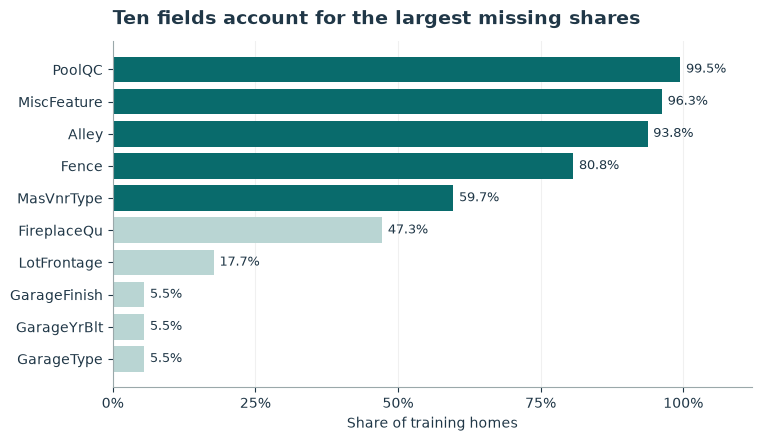

按数据字典，PoolQC、Alley 和 Fence 缺失通常代表没有相应设施。LotFrontage 等数值字段另行处理。


In [4]:
missing = train.drop(columns=["Id", "SalePrice"]).isna().mean().mul(100).nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.3), layout="constrained")
bars = ax.barh(missing.index, missing, color=[TEAL if value > 50 else PALE for value in missing])
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in missing], padding=4, fontsize=9)
ax.set(xlim=(0, 112), xlabel="Share of training homes", title="Ten fields account for the largest missing shares")
ax.set_xticks([0, 25, 50, 75, 100])
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.grid(axis="x", alpha=0.18)
show_figure(fig, "02_missingness.png")
print("按数据字典，PoolQC、Alley 和 Fence 缺失通常代表没有相应设施。LotFrontage 等数值字段另行处理。")

散点图中的每个点都是一笔交易，颜色代表房屋整体材料与装修质量评分。颜色和面积提供两种观察价格的角度。

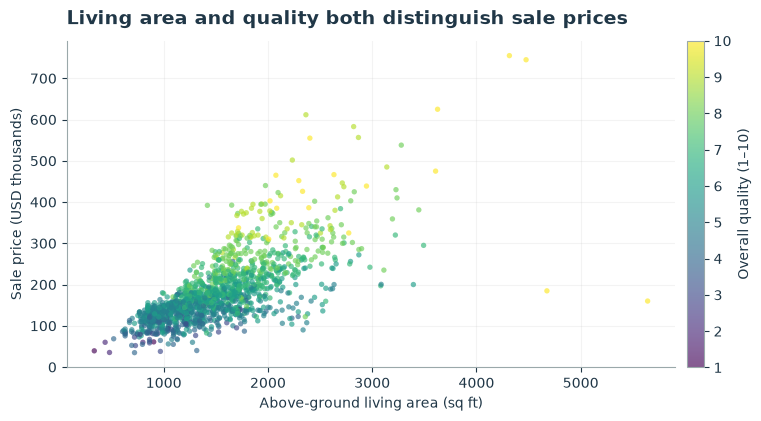

地上居住面积与价格的 Spearman 相关系数为 0.73。个别面积逾 4,000 平方英尺的低价交易也保留在验证中。


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.1), layout="constrained")
scatter = ax.scatter(train["GrLivArea"], price_k, c=train["OverallQual"], cmap="viridis",
                     s=15, alpha=0.65, edgecolors="none", rasterized=True)
colorbar = fig.colorbar(scatter, ax=ax, pad=.02)
colorbar.set_label("Overall quality (1–10)")
ax.set(xlabel="Above-ground living area (sq ft)", ylabel="Sale price (USD thousands)",
       title="Living area and quality both distinguish sale prices")
ax.grid(alpha=.15)
show_figure(fig, "03_area_and_price.png")
rho = train["GrLivArea"].corr(y, method="spearman")
print(f"地上居住面积与价格的 Spearman 相关系数为 {rho:.2f}。个别面积逾 4,000 平方英尺的低价交易也保留在验证中。")

## 3. 构造特征并定义三个模型

`make_features` 用单套房已有的字段计算房龄、翻修间隔、面积与卫浴数量，并给类别缺失加标记。街区中位价只读取训练折成交价。Ridge 在训练折拟合插补、标准化和独热编码。CatBoost 接收类别列名与保留数值缺失的表格。两种学习模型都拟合 `ln(SalePrice)`，再取指数还原美元。

In [6]:
CAT_COLS = train.drop(columns=["Id", "SalePrice"]).select_dtypes(exclude="number").columns.tolist() + ["MSSubClass"]
ABSENCE_FIELDS = {
    "Alley", "PoolQC", "Fence", "MiscFeature", "FireplaceQu", "MasVnrType", "BsmtQual", "BsmtCond",
    "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
}


def make_features(frame):
    # Id 只用于对齐。所有派生量都在单行内计算，不借用其他房屋的标签。
    x = frame.drop(columns=["Id", "SalePrice"], errors="ignore").copy()
    x["HouseAge"] = (x["YrSold"] - x["YearBuilt"]).clip(lower=0)
    x["YearsSinceRemodel"] = (x["YrSold"] - x["YearRemodAdd"]).clip(lower=0)
    x["TotalInteriorSF"] = x["GrLivArea"] + x["TotalBsmtSF"]
    x["TotalBaths"] = x["FullBath"] + x["BsmtFullBath"] + 0.5 * (x["HalfBath"] + x["BsmtHalfBath"])
    porch_cols = ["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]
    x["TotalPorchSF"] = x[porch_cols].sum(axis=1, min_count=len(porch_cols))
    for name in CAT_COLS:
        marker = "__ABSENT__" if name in ABSENCE_FIELDS else "__UNKNOWN__"
        x[name] = x[name].astype("string").fillna(marker).astype(str)
    for name in ("LotArea", "GrLivArea", "1stFlrSF", "TotalBsmtSF", "TotalInteriorSF", "LotFrontage"):
        x[name] = np.log1p(x[name])
    return x


X = make_features(train)
X_test = make_features(test)
assert X.columns.equals(X_test.columns)
NUM_COLS = [col for col in X.columns if col not in CAT_COLS]
BASE = "Neighborhood median"
LINEAR = "Ridge"
TREE = "CatBoost"
MODELS = [BASE, LINEAR, TREE]


def make_estimator(name):
    if name == LINEAR:
        # 插补与标准化放进 Pipeline，fit 只会看到当前训练折。
        numbers = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
        prep = ColumnTransformer(
            [("num", numbers, NUM_COLS), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)],
            sparse_threshold=1.0,
        )
        return make_pipeline(prep, Ridge(alpha=20.0, solver="lsqr", tol=1e-7))
    if name == TREE:
        return CatBoostRegressor(iterations=1000, depth=5, learning_rate=.045, l2_leaf_reg=5,
                                 loss_function="RMSE", cat_features=CAT_COLS, random_seed=SEED,
                                 thread_count=4, verbose=False, allow_writing_files=False)
    raise ValueError(f"未定义的模型 {name}")


def fit_predict(name, fit_x, fit_y, predict_x):
    if name == BASE:
        medians = fit_y.groupby(fit_x["Neighborhood"]).median()
        values = predict_x["Neighborhood"].map(medians).fillna(fit_y.median()).to_numpy(dtype=float)
    else:
        estimator = make_estimator(name)
        estimator.fit(fit_x, np.log(fit_y))
        values = np.exp(estimator.predict(predict_x))
    if not (np.isfinite(values).all() and (values > 0).all()):
        raise ValueError(f"{name} 产生了无效价格。")
    return values

## 4. 共享五折验证与比较

`KFold(5, shuffle=True, random_state=42)` 只生成一次索引。每次用四折训练，依次对相同的留出折预测。先求每折 Log RMSE 再做算术平均选模型。另将所有折外预测合并，计算美元误差和百分比误差。

In [7]:
def errors(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    absolute = np.abs(predicted - actual)
    log_rmse = np.sqrt(np.mean((np.log(predicted) - np.log(actual)) ** 2))
    ape = 100 * absolute / actual
    return {"LogRMSE": float(log_rmse), "MAE_USD": float(absolute.mean()),
            "MdAPE_pct": float(np.median(ape)), "P90_APE_pct": float(np.quantile(ape, .9)),
            "P90_AbsUSD": float(np.quantile(absolute, .9))}


splits = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X))
oof = pd.DataFrame(index=train.index, columns=MODELS, dtype=float)
fold_id = np.zeros(len(train), dtype=int)
fold_rows = []
for fold, (learn, valid) in enumerate(splits, start=1):
    assert not np.intersect1d(learn, valid).size and not fold_id[valid].any()
    fold_id[valid] = fold
    for name in MODELS:
        predictions = fit_predict(name, X.iloc[learn], y.iloc[learn], X.iloc[valid])
        oof.loc[valid, name] = predictions
        score = errors(y.iloc[valid], predictions)["LogRMSE"]
        fold_rows.append({"Fold": fold, "Model": name, "ValidationRows": len(valid), "LogRMSE": score})

assert (fold_id > 0).all() and oof.notna().all().all()
by_fold = pd.DataFrame(fold_rows)
comparison = by_fold.groupby("Model")["LogRMSE"].agg(MeanLogRMSE="mean", FoldSD="std").reindex(MODELS)
for name in MODELS:
    pooled = errors(y, oof[name])
    comparison.loc[name, "OOFLogRMSE"] = pooled.pop("LogRMSE")
    for metric, value in pooled.items():
        comparison.loc[name, metric] = value
winner = comparison["MeanLogRMSE"].idxmin()
comparison.to_csv(OUT / "model_comparison.csv", index_label="Model")
by_fold.to_csv(OUT / "fold_scores.csv", index=False)
oof_export = pd.concat([train[["Id", "SalePrice"]], pd.Series(fold_id, name="Fold"), oof], axis=1)
oof_export.to_csv(OUT / "oof_predictions.csv", index=False)
display(comparison.round({"MeanLogRMSE": 4, "FoldSD": 4, "OOFLogRMSE": 4, "MAE_USD": 0, "MdAPE_pct": 2}))
print(f"按五折平均 Log RMSE 选定 {winner}。每折训练 {len(splits[0][0]):,} 套，验证 {len(splits[0][1]):,} 套。")
fold_table = by_fold.pivot(index="Fold", columns="Model", values="LogRMSE")[MODELS]
display(fold_table.round(6))

,MeanLogRMSE,FoldSD,OOFLogRMSE,MAE_USD,MdAPE_pct,P90_APE_pct,P90_AbsUSD
Model,,,,,,,
Neighborhood median,0.2690,0.0105,0.2691,36232.0,14.58,45.227723,81000.000000
Ridge,0.1317,0.0320,0.1348,15414.0,5.61,16.360941,30564.041771
CatBoost,0.1253,0.0170,0.1263,14859.0,5.58,16.609009,28820.396550


按五折平均 Log RMSE 选定 CatBoost。每折训练 1,168 套，验证 292 套。


Model,Neighborhood median,Ridge,CatBoost
Fold,,,
1,0.272873,0.130710,0.130877
2,0.268313,0.114966,0.111454
3,0.261901,0.186495,0.150087
4,0.284421,0.120688,0.126746
5,0.257384,0.105653,0.107571


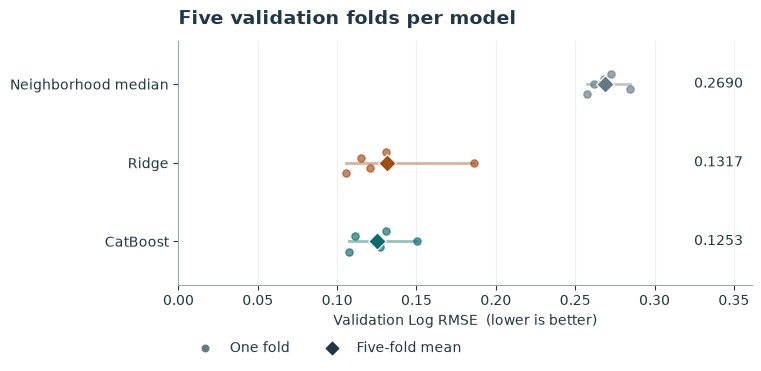

CatBoost 在 2 折优于 Ridge。两者差距最大的是第 3 折。


In [8]:
colors = [MUTED, AMBER, TEAL]
fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
for row, (name, color) in enumerate(zip(MODELS, colors)):
    values = by_fold.loc[by_fold["Model"].eq(name), "LogRMSE"].to_numpy()
    ax.plot([values.min(), values.max()], [row, row], color=color, alpha=.42, linewidth=2)
    ax.scatter(values, row + np.linspace(-.13, .13, len(values)), s=27, marker="o", color=color, alpha=.65)
    mean = comparison.loc[name, "MeanLogRMSE"]
    ax.scatter([mean], [row], s=80, marker="D", color=color, edgecolors="white", linewidth=.9, zorder=4)
    ax.text(.985, row, f"{mean:.4f}", ha="right", va="center", transform=ax.get_yaxis_transform(), color=INK)
axis_max = by_fold["LogRMSE"].max()
ax.set(xlim=(0, axis_max * 1.27), yticks=range(len(MODELS)), yticklabels=MODELS,
       ylim=(-.55, len(MODELS)-.45), xlabel="Validation Log RMSE  (lower is better)",
       title="Five validation folds per model")
ax.invert_yaxis()
ax.grid(axis="x", alpha=.18)
ax.scatter([], [], color=MUTED, marker="o", s=22, label="One fold")
ax.scatter([], [], color=INK, marker="D", s=40, label="Five-fold mean")
ax.legend(frameon=False, ncols=2, loc="upper left", bbox_to_anchor=(0,-.18))
show_figure(fig, "04_model_comparison.png")
gains = fold_table[LINEAR] - fold_table[TREE]
print(f"CatBoost 在 {(gains > 0).sum()} 折优于 Ridge。两者差距最大的是第 {gains.abs().idxmax()} 折。")

## 5. 折外误差与最大的失误

对角线表示预测等于成交价，位于线上方的房屋被高估。接着按实际价格分四组，看偏差方向，并直接核查绝对误差最大的房屋。

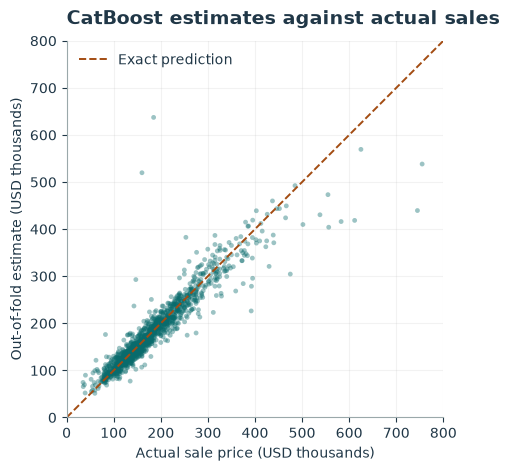

折外预测高于成交价 691 套，低于成交价 769 套。


In [9]:
winning_oof = oof[winner]
pred_k = winning_oof / 1000
upper = np.ceil(max(price_k.max(), pred_k.max()) / 100) * 100
fig, ax = plt.subplots(figsize=(6.5, 4.6), layout="constrained")
ax.scatter(price_k, pred_k, s=12, alpha=.40, color=TEAL, edgecolors="none", rasterized=True)
ax.plot([0, upper], [0, upper], color=AMBER, linestyle="--", linewidth=1.4, label="Exact prediction")
ax.set(xlim=(0, upper), ylim=(0, upper), xlabel="Actual sale price (USD thousands)",
       ylabel="Out-of-fold estimate (USD thousands)", title=f"{winner} estimates against actual sales")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=.16)
ax.legend(frameon=False, loc="upper left")
show_figure(fig, "05_predicted_vs_actual.png")
print(f"折外预测高于成交价 {(winning_oof > y).sum()} 套，低于成交价 {(winning_oof < y).sum()} 套。")

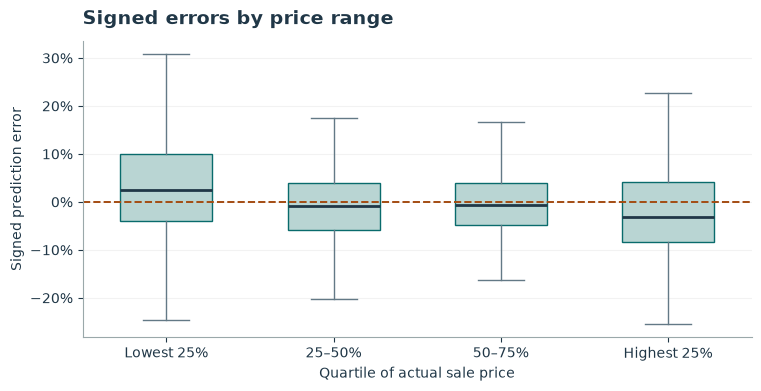

低价四分位的误差中位数为 +2.5%，高价四分位为 -3.1%。
箱体覆盖中间一半房屋，须线延伸至 1.5 倍四分位距范围内的最远观测。极端点参与全部统计指标。


In [10]:
quartile = pd.qcut(y, q=4, labels=False)
signed_pct = (winning_oof / y - 1) * 100
median_pct = signed_pct.groupby(quartile).median()
groups = [signed_pct[quartile.eq(i)].to_numpy() for i in range(4)]
fig, ax = plt.subplots(figsize=(7.5, 3.8), layout="constrained")
ax.boxplot(groups, patch_artist=True, showfliers=False, widths=.55,
           boxprops={"facecolor": PALE, "edgecolor": TEAL}, medianprops={"color": INK, "linewidth": 2},
           capprops={"color": MUTED}, whiskerprops={"color": MUTED})
ax.axhline(0, color=AMBER, linestyle="--", linewidth=1.4)
ax.set_xticks([1, 2, 3, 4], ["Lowest 25%", "25–50%", "50–75%", "Highest 25%"])
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set(xlabel="Quartile of actual sale price", ylabel="Signed prediction error",
       title="Signed errors by price range")
ax.grid(axis="y", alpha=.16)
show_figure(fig, "06_error_by_price_range.png")
print(f"低价四分位的误差中位数为 {median_pct.iloc[0]:+.1f}%，高价四分位为 {median_pct.iloc[-1]:+.1f}%。")
print("箱体覆盖中间一半房屋，须线延伸至 1.5 倍四分位距范围内的最远观测。极端点参与全部统计指标。")

### 误差较大的一成房屋

下表专门核查 CatBoost。正美元误差代表高估。第 90 百分位按线性插值计算，尾部取严格超过阈值的样本。每套房对所在折的对数平方误差贡献可以相加。

In [11]:
features_for_review = ["Id", "Neighborhood", "GrLivArea", "OverallQual", "SaleCondition"]
audit = oof_export[["Id", "Fold", "SalePrice", TREE]].merge(
    train[features_for_review], on="Id", validate="one_to_one", how="left")
audit["SignedError_USD"] = audit[TREE] - audit["SalePrice"]
audit["AbsError_USD"] = audit["SignedError_USD"].abs()
audit["APE_pct"] = 100 * audit["AbsError_USD"] / audit["SalePrice"]
audit["SquaredLogError"] = (np.log(audit[TREE]) - np.log(audit["SalePrice"])) ** 2
fold_sse = audit.groupby("Fold")["SquaredLogError"].transform("sum")
audit["ShareOfFoldLogSSE_pct"] = 100 * audit["SquaredLogError"] / fold_sse
cutoff = audit["APE_pct"].quantile(.90)
audit["AboveP90_APE"] = audit["APE_pct"].gt(cutoff)
audit.sort_values("APE_pct", ascending=False).to_csv(OUT / "catboost_errors.csv", index=False)
tail = audit.loc[audit["AboveP90_APE"]]
print(f"绝对百分比误差 P90 为 {cutoff:.2f}%，绝对美元误差 P90 为 ${audit['AbsError_USD'].quantile(.9):,.0f}。")
print(f"超过百分比阈值的 {len(tail)} 套中，{tail['SignedError_USD'].gt(0).sum()} 套高估，"
      f"{tail['SignedError_USD'].lt(0).sum()} 套低估。这组的绝对百分比误差中位数为 {tail['APE_pct'].median():.2f}%。")
display(audit.nlargest(5, "APE_pct")[["Id", "Fold", "GrLivArea", "OverallQual", "SaleCondition", "SalePrice", TREE, "SignedError_USD", "APE_pct"]].round(2))
pair = audit.loc[audit["Id"].isin([524, 1299])]
assert len(pair) == 2 and pair["Fold"].eq(3).all()
print(f"Id 524 和 1299 合计占第 3 折对数平方误差的 {pair['ShareOfFoldLogSSE_pct'].sum():.2f}%。")

绝对百分比误差 P90 为 16.61%，绝对美元误差 P90 为 $28,820。
超过百分比阈值的 146 套中，90 套高估，56 套低估。这组的绝对百分比误差中位数为 23.84%。


,Id,Fold,GrLivArea,OverallQual,SaleCondition,SalePrice,CatBoost,SignedError_USD,APE_pct
523,524,3,4676,10,Partial,184750,637293.10,452543.10,244.95
1298,1299,3,5642,10,Partial,160000,519730.74,359730.74,224.83
30,31,1,1317,4,Normal,40000,89790.32,49790.32,124.48
632,633,5,1411,7,Family,82500,176224.31,93724.31,113.61
495,496,4,720,4,Abnorml,34900,74486.22,39586.22,113.43


Id 524 和 1299 合计占第 3 折对数平方误差的 44.41%。


## 6. 全量重训与提交

依据五折平均 Log RMSE 选出的模型重新学习全部 1,460 笔成交，再预测 1,459 套竞赛测试房屋。按 `sample_submission.csv` 的 `Id` 排列价格，并读回磁盘文件检查。

In [12]:
test_predictions = fit_predict(winner, X, y, X_test)
lookup = pd.Series(test_predictions, index=test["Id"])
submission = pd.DataFrame({"Id": sample["Id"], "SalePrice": sample["Id"].map(lookup)})
submission.to_csv(OUT / "submission.csv", index=False, float_format="%.2f", lineterminator="\n")
checked = pd.read_csv(OUT / "submission.csv")
assert list(checked.columns) == ["Id", "SalePrice"] and checked["Id"].equals(sample["Id"])
assert len(checked) == 1459 and checked["Id"].is_unique
assert np.isfinite(checked["SalePrice"]).all() and checked["SalePrice"].gt(0).all()
assert np.allclose(checked["SalePrice"], submission["SalePrice"], rtol=0, atol=.005001)
display(checked.head())
print(f"submission.csv 已包含 {len(checked):,} 个预测，Id 从 {checked.Id.iloc[0]} 到 {checked.Id.iloc[-1]}。")

,Id,SalePrice
0,1461,119168.33
1,1462,160741.68
2,1463,184776.69
3,1464,195078.82
4,1465,185920.18


submission.csv 已包含 1,459 个预测，Id 从 1461 到 2919。


## 7. 结论与适用范围

CatBoost 的五折平均 Log RMSE 为 0.125347，相对街区中位价降低 53.40%，相对 Ridge 降低 4.83%。优势集中在与 Ridge 第 3 折的比较。CatBoost 自身也在这一折最困难。Id 524 和 1299 两笔高估占该折对数平方误差的 44.41%。

随机五折对应同一历史市场。选模型和报告成绩使用同一批折，无标签竞赛测试集的成绩由 Kaggle 评定。主实验 CatBoost 的 Kaggle 官方 Public Score 为 **0.12233**（提交编号 `58516821`）。 更多验证边界与已做的后续实验见[实验报告](docs/experiment_report.md)。